We're solving a binary classification problem where we predict if bank customers will default on their loans - meaning they fail to pay back the money they borrowed. We use tree-based algorithms like decision trees, random forests, and gradient boosting to make these predictions. First, we clean the data by fixing column names and decoding number codes into readable categories like changing '1' and '2' to 'ok' and 'default'. Then we explore the data to understand patterns before training our models. Finally, we evaluate how well our models can separate good borrowers from risky ones using AUC scores, which tells us how good our detective is at spotting potential defaulters.

import the usual Python data stack. Short explanation: pandas for tables, numpy for arrays/math, seaborn + matplotlib for plotting. %matplotlib inline is an IPython magic so plots show up inside the notebook — yeah, it only works in notebooks. If you run this as a script, remove the magic or use a different backend.

In [ ]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline


Read the CSV into a DataFrame. This assumes the notebook’s working directory is where CreditScoring.csv lives. If not, either give the full path or change directory first. pd.read_csv makes a DataFrame object — that’s the central data structure.

In [ ]:
df = pd.read_csv('CreditScoring.csv')


Lowercase column names so they’re consistent and easier to type later.

In [ ]:
df.columns = df.columns.str.lower()


Peek at the top rows. df.head() shows the first five rows by default.

In [ ]:
df.head()


,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


# What the columns mean

Here are the important columns and what they tell us:

status — did the person pay back the loan? (coded as 1, 2, or 0 in the file)

seniority — how many years they worked at the job

home — type of home (rent, owner, etc.)

time — loan length in months

age — the person’s age

marital — married or single (coded numbers)

records — any previous records? (yes/no)

job — job type (full-time, part-time, freelance)

expenses — monthly spending

income — monthly income

assets — total assets

debt — amount of other credit debt

amount — how much they asked to borrow

price — price of the item they want to buy

In the CSV these categories are numbers (like 1 or 2). We want words (like 'ok', 'default', 'rent') because they’re easier to read and less confusing.

# Change the numbers to words (mapping)

We’ll replace those number codes with real words. Copy and run these mapping dictionaries and the code that applies them:

In [ ]:
# status: 1 -> ok, 2 -> default, 0 -> unk (unknown)
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}
df.status = df.status.map(status_values)

# home ownership mapping
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}
df.home = df.home.map(home_values)

# marital status mapping
marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}
df.marital = df.marital.map(marital_values)

# records mapping (has previous records in bank?)
records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}
df.records = df.records.map(records_values)

# job type mapping
job_values = {
    1: 'fixed',     # full-time
    2: 'parttime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}
df.job = df.job.map(job_values)


peek at the data to see if the columns have changed to categorical values.

In [ ]:
df.head()


,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


# Peek at the numbers

In [ ]:
# show summary statistics (nice rounded numbers)
df.describe().round()


,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


This prints a small table that tells you, for each numeric column: how many values there are, the average (mean), min, max, and the values at 25%, 50% (median) and 75%.

When you run it you may notice something strange: some columns (like income, assets, debt) have a very large maximum value 99999999. That’s not a real money value — it’s a placeholder meaning “missing”.

# Replace the giant placeholder with real missing values

We’ll replace 99999999 with NaN (which stands for “Not a Number” — our way to mark missing). Do this for the three columns that use this placeholder:

In [ ]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)


Now you should see more reasonable maximums and averages for income, assets, and debt. Also the count for those columns may be a little smaller because some values were turned into missing (NaN).

In [ ]:
df.describe().round()


,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


# Check the target (status) counts and remove the unknown row

In [ ]:
df.status.value_counts()


,count
status,
ok,3200
default,1254
unk,1


That means there is one row where we don’t know if the person paid or not (unk). This row is not useful for training because our robot needs to see examples labeled as ok or default. So we remove it:

In [ ]:
df = df[df.status != 'unk']


This line creates a new table with only rows where status is not unk — so the unknown row is gone.

# Prepare the data for learning (split, missing values, and turn words into numbers)

Split the dataset into train, validation, and test sets
We want three groups:

Train (60%): where the robot learns.

Validation (20%): where we try different settings and see which is best.

Test (20%): the final exam — used only once at the end.

Because train_test_split splits into two parts at a time, we do it twice:

In [ ]:
from sklearn.model_selection import train_test_split

# first hold out 20% for test
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=11)

# then split the remaining 80% into train (60% total) and val (20% total)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=11)

# check sizes
len(df_train), len(df_val), len(df_test)


(2672, 891, 891)

# Create the target variables (y)

We want y to be 1 if the person defaulted and 0 otherwise. Do this:

In [ ]:
y_train = (df_train.status == 'default').values
y_val   = (df_val.status == 'default').values


This turns status into True/False and then into 1/0 numbers the robot likes.
Now remove the status column from the feature tables so the robot doesn’t accidentally “cheat”:

In [ ]:
del df_train['status']
del df_val['status']


# Handle missing values (fill NaNs)

We replaced 99999999 with NaN earlier. Many simple models can’t handle NaN, so we’ll replace missing numbers with 0 for now:

In [ ]:
df_train = df_train.fillna(0)
df_val   = df_val.fillna(0)


# Turn categorical words into numbers (one-hot encoding)

Our categorical columns (like home, job, records) are words now. The robot needs numbers. We use one-hot encoding: make a new column for each category value and put 1 if it’s that value, otherwise 0.

We’ll use DictVectorizer which expects a list of Python dictionaries (one dict per row). First convert:

In [ ]:
dict_train = df_train.to_dict(orient='records')
dict_val   = df_val.to_dict(orient='records')


A single record (row) may look like:

In [ ]:
{'seniority': 10,
 'home': 'owner',
 'time': 36,
 'age': 36,
 'marital': 'married',
 'records': 'no',
 'job': 'freelance',
 'expenses': 75,
 'income': 0.0,
 'assets': 10000.0,
 'debt': 0.0,
 'amount': 1000,
 'price': 1400}


{'seniority': 10,
 'home': 'owner',
 'time': 36,
 'age': 36,
 'marital': 'married',
 'records': 'no',
 'job': 'freelance',
 'expenses': 75,
 'income': 0.0,
 'assets': 10000.0,
 'debt': 0.0,
 'amount': 1000,
 'price': 1400}

Now we vectorize (turn those dicts into a numeric matrix):

In [ ]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(dict_train)
X_val   = dv.transform(dict_val)


dv.fit_transform looks at all categories in the training data and creates the numeric columns.

dv.transform applies the same mapping to the validation set.

Now X_train and X_val are numeric tables your robot can use. Each column is either a numeric feature (like age) or one of the new one-hot columns (like job=freelance).

now, to the decision tree. A decision tree is a stack of simple if-then rules that lead to a decision.

# Train a Decision Tree with scikit-learn

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

# create the classifier with default settings
dt = DecisionTreeClassifier()

# train it on our numeric matrices
dt.fit(X_train, y_train)

# compute scores (probabilities) for train and validation
y_pred_train = dt.predict_proba(X_train)[:, 1]   # probability of 'default'
y_pred_val   = dt.predict_proba(X_val)[:, 1]

print('train auc', roc_auc_score(y_train, y_pred_train))
print('validation auc', roc_auc_score(y_val, y_pred_val))


train auc 1.0
validation auc 0.6613396381778112


What this code does

*DecisionTreeClassifier() creates the tree-robot.
.fit(X_train, y_train) teaches the robot using the training examples.
.predict_proba(...) asks the robot “what’s the chance this person will default?” — we use that to compute the AUC (a score that measures how good the robot is at putting risky people above safe people).

That means the robot scored 100% on its training examples (it memorized them), but only 65% on the validation set (new people it hadn’t seen). This is a sign of overfitting.

# Make the tree simpler (prevent overfitting)

We can stop the tree from growing too deep by setting max_depth. A smaller tree asks fewer questions and is less likely to over-memorize.

In [ ]:
from sklearn.tree import export_text

# make a small tree with max depth = 2
dt_small = DecisionTreeClassifier(max_depth=2)
dt_small.fit(X_train, y_train)

# print the tree as text (readable rules)
tree_text = export_text(dt_small, feature_names=dv.feature_names_)
print(tree_text)

# evaluate it
y_pred_train = dt_small.predict_proba(X_train)[:, 1]
y_pred_val   = dt_small.predict_proba(X_val)[:, 1]
print('train auc:', roc_auc_score(y_train, y_pred_train))
print('validation auc:', roc_auc_score(y_val, y_pred_val))


|--- records=yes <= 0.50
|   |--- job=parttime <= 0.50
|   |   |--- class: False
|   |--- job=parttime >  0.50
|   |   |--- class: True
|--- records=yes >  0.50
|   |--- seniority <= 6.50
|   |   |--- class: True
|   |--- seniority >  6.50
|   |   |--- class: False

train auc: 0.7054989859726213
validation auc: 0.6685264343319367


So the training AUC dropped (the robot no longer memorizes perfectly), but the validation AUC improved a bit (it generalized better). That’s good — simpler model, better real-world use.

# Tuning the Decision Tree

Think of the decision tree as a question-asking machine. Two big knobs control how picky it is:

max_depth — how many questions it can ask in a row (how deep the tree can get).

Small depth = few questions = simple rules.

Big depth = lots of questions = can become a memorizer.

min_samples_leaf (called min_samples_leaf) — the minimum number of people a final answer (leaf) must have.

If this is small (like 1), the tree can make a leaf that fits just one person — that’s memorizing.

If it’s bigger (like 15), each leaf must represent many people, so it learns more general rules.

We’ll try different values for these knobs, check how the robot does on the validation set, and pick the settings that give the best score (AUC).

# Try different tree depths

This loop runs many depths:

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

for depth in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    print('%4s -> %.3f' % (depth, auc))


   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.767
   6 -> 0.758
  10 -> 0.669
  15 -> 0.658
  20 -> 0.650
None -> 0.648


Depth 5 gave the best validation score 0.766 (76.6%).

Too deep (like None, 20) the tree overfit and did worse on validation.

Too shallow (1 or 2) it was too simple and also did worse.

So depth = 5 looked like a good start.

# different min_samples_leaf values together with good depths

We saw depth 5 was good, but depth 6 also looked close. Let’s test a small grid: depths 4, 5, 6 and various min_samples_leaf values.

In [ ]:
for m in [4, 5, 6]:
    print('depth:', m)
    for s in [1, 5, 10, 15, 20, 50, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=m, min_samples_leaf=s)
        dt.fit(X_train, y_train)
        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        print('%s -> %.3f' % (s, auc))
    print()


depth: 4
1 -> 0.761
5 -> 0.761
10 -> 0.761
15 -> 0.764
20 -> 0.761
50 -> 0.753
100 -> 0.756
200 -> 0.747

depth: 5
1 -> 0.767
5 -> 0.768
10 -> 0.762
15 -> 0.772
20 -> 0.774
50 -> 0.768
100 -> 0.763
200 -> 0.759

depth: 6
1 -> 0.760
5 -> 0.762
10 -> 0.778
15 -> 0.785
20 -> 0.773
50 -> 0.772
100 -> 0.776
200 -> 0.768



The best AUC in this grid is 0.785 (78.5%) with:

max_depth = 6

min_samples_leaf = 15

Even though depth 5 was the best when we only varied depth, when we allowed larger leaves the combination depth=6 + leaf=15 gave the best validation score. That’s why we do a small grid search — knobs interact!

# Train the final tuned decision tree

In [ ]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)

You can evaluate it on validation:

In [ ]:
y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)   # should be ~0.785 (78.5%)


np.float64(0.7853194400716863)

# Random Forests

To make trees different, each tree looks at a different random subset of the features (different columns), so they’re not all the same.

# Train a simple Random Forest

Here’s the basic code to train a small forest of 10 trees and check how well it performs on validation:

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# make a small random forest
rf = RandomForestClassifier(n_estimators=10)
rf.fit(X_train, y_train)

# evaluate on validation
y_pred = rf.predict_proba(X_val)[:, 1]
print('validation auc', roc_auc_score(y_val, y_pred))


validation auc 0.7902842023685549


# Randomness & reproducibility

Because the forest chooses random feature subsets, training the same code twice can give slightly different results. If you want the exact same result every time, set the random_state parameter:


In [ ]:
rf = RandomForestClassifier(n_estimators=10, random_state=3)
rf.fit(X_train, y_train)


RandomForestClassifier(n_estimators=10, random_state=3)

With random_state=3, the random choices are controlled, and the model gives the same output each time you train it.

Usually more trees help, but beyond some point you don’t get much better. Let’s measure validation AUC while changing the number of trees from 10 to 200

10 -> 0.781
20 -> 0.801
30 -> 0.813
40 -> 0.815
50 -> 0.816
60 -> 0.817
70 -> 0.818
80 -> 0.818
90 -> 0.820
100 -> 0.819
110 -> 0.819
120 -> 0.821
130 -> 0.822
140 -> 0.822
150 -> 0.820
160 -> 0.820
170 -> 0.819
180 -> 0.820
190 -> 0.820
200 -> 0.820


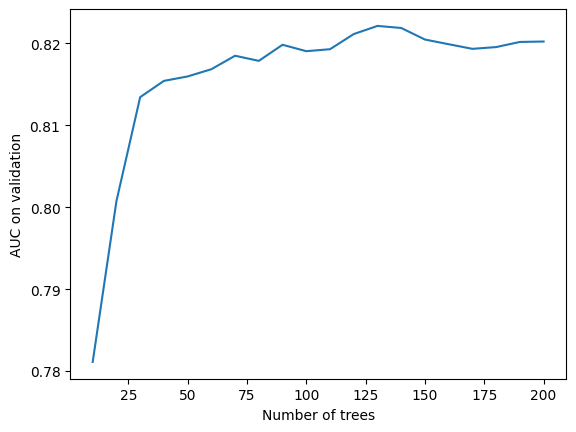

In [ ]:
aucs = []

for i in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=i, random_state=3)
    rf.fit(X_train, y_train)
    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    print('%s -> %.3f' % (i, auc))
    aucs.append(auc)

# plot result
plt.plot(range(10, 201, 10), aucs)
plt.xlabel('Number of trees')
plt.ylabel('AUC on validation')
plt.show()


# Tune Random Forest parameters (depth and leaf size)

Just like with decision trees, random forest has knobs we can tune:

max_depth — how deep each tree can grow.

min_samples_leaf — minimum samples per leaf.

We try a few depths (5, 10, 20) and see how AUC grows with more trees:

In [ ]:
all_aucs = {}

for depth in [5, 10, 20]:
    print('depth:', depth)
    aucs = []
    for i in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=i, max_depth=depth, random_state=1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        print('%s -> %.3f' % (i, auc))
        aucs.append(auc)
    all_aucs[depth] = aucs
    print()


depth: 5
10 -> 0.788
20 -> 0.798
30 -> 0.800
40 -> 0.800
50 -> 0.800
60 -> 0.801
70 -> 0.802
80 -> 0.803
90 -> 0.804
100 -> 0.804
110 -> 0.807
120 -> 0.806
130 -> 0.808
140 -> 0.807
150 -> 0.807
160 -> 0.807
170 -> 0.807
180 -> 0.807
190 -> 0.807
200 -> 0.807

depth: 10
10 -> 0.791
20 -> 0.808
30 -> 0.812
40 -> 0.818
50 -> 0.817
60 -> 0.819
70 -> 0.820
80 -> 0.820
90 -> 0.820
100 -> 0.821
110 -> 0.823
120 -> 0.823
130 -> 0.825
140 -> 0.824
150 -> 0.824
160 -> 0.825
170 -> 0.825
180 -> 0.825
190 -> 0.825
200 -> 0.825

depth: 20
10 -> 0.776
20 -> 0.803
30 -> 0.813
40 -> 0.817
50 -> 0.815
60 -> 0.813
70 -> 0.814
80 -> 0.815
90 -> 0.814
100 -> 0.815
110 -> 0.817
120 -> 0.816
130 -> 0.818
140 -> 0.818
150 -> 0.818
160 -> 0.818
170 -> 0.817
180 -> 0.817
190 -> 0.817
200 -> 0.818



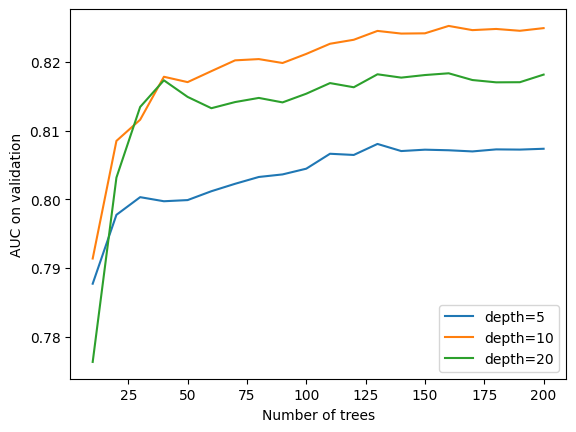

In [ ]:
num_trees = list(range(10, 201, 10))
plt.plot(num_trees, all_aucs[5], label='depth=5')
plt.plot(num_trees, all_aucs[10], label='depth=10')
plt.plot(num_trees, all_aucs[20], label='depth=20')
plt.legend()
plt.xlabel('Number of trees')
plt.ylabel('AUC on validation')
plt.show()


Tune min_samples_leaf (with max_depth=10)
Now fix max_depth=10 and try different min_samples_leaf values (e.g., 3, 5, 10):

min_samples_leaf: 3
10 -> 0.811
30 -> 0.823
50 -> 0.823
70 -> 0.822
90 -> 0.823
110 -> 0.823
130 -> 0.824
150 -> 0.825
170 -> 0.825
190 -> 0.825

min_samples_leaf: 5
10 -> 0.813
30 -> 0.818
50 -> 0.821
70 -> 0.822
90 -> 0.822
110 -> 0.825
130 -> 0.825
150 -> 0.825
170 -> 0.825
190 -> 0.826

min_samples_leaf: 10
10 -> 0.810
30 -> 0.822
50 -> 0.822
70 -> 0.819
90 -> 0.820
110 -> 0.820
130 -> 0.821
150 -> 0.820
170 -> 0.820
190 -> 0.820



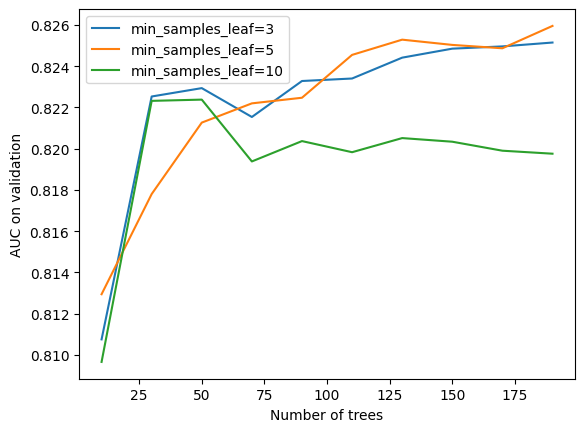

In [ ]:
all_aucs = {}

for m in [3, 5, 10]:
    print('min_samples_leaf:', m)
    aucs = []
    for i in range(10, 201, 20):
        rf = RandomForestClassifier(n_estimators=i, max_depth=10, min_samples_leaf=m, random_state=1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        print('%s -> %.3f' % (i, auc))
        aucs.append(auc)
    all_aucs[m] = aucs
    print()

# plot
num_trees = list(range(10, 201, 20))
plt.plot(num_trees, all_aucs[3], label='min_samples_leaf=3')
plt.plot(num_trees, all_aucs[5], label='min_samples_leaf=5')
plt.plot(num_trees, all_aucs[10], label='min_samples_leaf=10')
plt.legend()
plt.xlabel('Number of trees')
plt.ylabel('AUC on validation')
plt.show()


# Train the final Random Forest

In [ ]:
rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5, random_state=1)
rf.fit(X_train, y_train)

# evaluate
y_pred = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)   # ~0.825 or ~82.5%


np.float64(0.8253826499721489)

The tuned random forest gets about 82.5% AUC on validation, better than the single decision tree but a little worse than the best XGBoost after tuning.

# Gradient boosting (XGBoost)

Gradient Boosting = train one expert, see where they’re wrong, then train a new expert to fix those mistakes, then train another to fix what’s left, and so on. It’s like doing homework, checking mistakes, and correcting them again and again.

XGBoost is a very good, fast tool that builds these fixing-trees.

In [ ]:
pip install xgboost


In [ ]:
import xgboost as xgb


# Prepare data for XGBoost (DMatrix)

XGBoost likes a special format called DMatrix. Make those from the X_train, y_train, etc., that you already created:

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=dv.feature_names_)
dval   = xgb.DMatrix(X_val,   label=y_val,   feature_names=dv.feature_names_)


feature_names=dv.feature_names_ helps XGBoost know the original column names.

Here’s a simple parameter set and a quick training for 10 trees:

In [ ]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'nthread': 8,
    'seed': 1,
    'silent': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10)
y_pred = model.predict(dval)
from sklearn.metrics import roc_auc_score
roc_auc_score(y_val, y_pred)   # example: ~0.815 (81.5%)


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [17:37:28] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "silent" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


np.float64(0.8118506454190986)

# Watchlist: see how performance changes as trees grow

Use a watchlist to monitor training and validation AUC each few rounds:

In [ ]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

xgb_params['eval_metric'] = 'auc'

model = xgb.train(xgb_params, dtrain,
                  num_boost_round=100,
                  evals=watchlist, verbose_eval=10)


[0]	train-auc:0.86653	val-auc:0.77999
[10]	train-auc:0.95512	val-auc:0.81115
[20]	train-auc:0.97648	val-auc:0.81877
[30]	train-auc:0.98844	val-auc:0.81613
[40]	train-auc:0.99393	val-auc:0.81407
[50]	train-auc:0.99723	val-auc:0.81276


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [17:37:28] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "silent" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[60]	train-auc:0.99861	val-auc:0.81244
[70]	train-auc:0.99962	val-auc:0.81243
[80]	train-auc:0.99989	val-auc:0.81359
[90]	train-auc:0.99998	val-auc:0.81038
[99]	train-auc:0.99999	val-auc:0.80838


# The learning rate (eta) — what it does

Eta controls how much each new tree adjusts the model, where smaller values like 0.1 learn more carefully but need more trees. Testing different settings showed max_depth=3 worked best for this data, preventing overfitting while achieving 83.6% accuracy. The best balance came from eta=0.1 with max_depth=3, giving strong results without requiring too many trees or complex tuning.

# Pick the best number of trees (where validation peaks)

Using the tuned params (eta=0.1, max_depth=3, min_child_weight=1), monitor the validation AUC and pick the iteration where val AUC is highest.

# Final model: retrain on train+validation and test

Now retrain the final XGBoost using combined training+validation data (so model sees more examples), and then evaluate on the test set.

In [ ]:
# prepare combined train (df_train_full was earlier the combined train+val)
# assume you've prepared X_train (from df_train_full) and X_test similarly
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=dv.feature_names_)
dtest  = xgb.DMatrix(X_test,  label=y_test,  feature_names=dv.feature_names_)

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1,
    'silent': 1
}

num_trees = 180   # choose the iteration where val AUC peaked
model = xgb.train(xgb_params, dtrain, num_boost_round=num_trees)

y_pred_xgb = model.predict(dtest)
roc_auc_score(y_test, y_pred_xgb)   # book example: ~0.832 (83.2%) with a similar setup


np.float64(0.823860026391672)

In [ ]:
# create final target vectors for the combined training set and the test set
y_train = (df_train_full.status == 'default').values
y_test  = (df_test.status == 'default').values

# remove status column from feature tables
del df_train_full['status']
del df_test['status']

# convert to dicts and vectorize (same DictVectorizer)
dict_train = df_train_full.fillna(0).to_dict(orient='records')
dict_test  = df_test.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(dict_train)
X_test  = dv.transform(dict_test)

# wrap into XGBoost DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=dv.feature_names_)
dtest  = xgb.DMatrix(X_test,  label=y_test,  feature_names=dv.feature_names_)

# final parameters (as tuned)
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1,
    'silent': 1
}

# number of trees — choose the iteration where val AUC peaked (book: 180)
num_trees = 180

model = xgb.train(xgb_params, dtrain, num_boost_round=num_trees)

# predict and evaluate on the test set
y_pred_xgb = model.predict(dtest)
from sklearn.metrics import roc_auc_score
print('test AUC:', roc_auc_score(y_test, y_pred_xgb))


test AUC: 0.8312521382141635


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [17:37:28] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "silent" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


the test AUC was ≈ 83.2%, which is close to the validation best (~83.6%). That means the model generalized well — it didn’t just memorize the training data.